# Basics of QC: A practical Workshop

The goal of this workshop is to provide a practical first encounter with quantum computing and to develop an intuition for how quantum algorithms are constructed. Our approach is to start with small computational problems, build simple quantum circuits, experiment with them in Qiskit, and gradually introduce the concepts needed to understand why they work: **“run first, explain later”**. 

A useful mindset is to imagine being a curious learner exploring classical computers several decades ago: rather than starting with modern processors and complex software, you might have asked how a 4-bit adder or a simple multiplier could be constructed from basic logical gates such as AND, OR, and NOT. We will approach quantum computing with the same curiosity, starting from its basic building blocks and exploring how they can be combined to perform computation. The objective is therefore not only to learn how to use quantum circuits, but also to begin thinking about computation from a quantum perspective.

<img src="pix/adder_4bit.png" alt="4-bit adder logic-gate circuit" width="700">

<br>
<div style="text-align: center;margin: 35px 0;font-size: 30px;font-weight: 600;letter-spacing: 3px;">

    ✦✦ PART TWO ✦✦

</div>

### Review

- We started with a simple computational question: **Is $f:\{0,1\}\rightarrow\{0,1\}$ constant or balanced?**

- We found out that 
  - A deterministic classical algorithm needs two queries.
  - Deutsch's quantum algorithm needs only one query.

- We implemented the solution using a **two-qubit quantum circuit**.
- We used quantum gates without yet studying all of their mathematical details.
- We executed the circuit using **Qiskit** and interpreted its measurement.

---

### Where Do We Go From Here?

- We have seen that the circuit works, but many questions remain:

  - What exactly is a **qubit**?
  - What does the $X$ gate do?
  - What does the $H$ gate do?
  - What does a CNOT do?
  - What happens when we use two qubits together?
  - What exactly is the quantum oracle $U_f$?
  - How can Deutsch's algorithm obtain the answer with only one query?
  - What roles do **quantum parallelism** and **phase kickback** play?

> These questions will guide us through the fundamental concepts of quantum computing.

---

### The X Operation

- Let us start with one of the simplest quantum operations: the **X gate**.
- The $X$ gate operates on a single qubit.
- For now, consider a qubit that is definitely in one of the two states: $\ket{0}$ or $\ket{1}$

- The $X$ gate simply **flips** these two states: $\ket{0} \rightarrow \ket{1}$ and $\ket{1} \rightarrow \ket{0}$
- This is written like: $X\ket{0}=\ket{1}$ and $X\ket{1}=\ket{0}$

---


### X in a Quantum Circuit

- In a quantum circuit, a qubit is represented by a horizontal line.
- A quantum operation is placed on that line.
- The $X$ symbol represents the $X$ gate.
- The circuit is read from **left to right**.

- Starting with $\ket{0}$:

  $$
  \ket{0} \xrightarrow{X} \ket{1}
  $$

- Applying $X$ again:

  $$
  \ket{0} \xrightarrow{X} \ket{1} \xrightarrow{X} \ket{0}
  $$

- Therefore, applying $X$ twice brings us back to the original state:

  $$
  X(X\ket{0})=\ket{0}
  $$

- We can express this more generally as:

  $$
  X^2 = I
  $$

  where $I$ means: **do nothing to the state**.

---

### But What Exactly Are We Manipulating?

- We have written expressions such as:

  $$
  X\ket{0}=\ket{1}
  $$

  and

  $$
  X^2=I
  $$

- But what exactly are $X$, $I$, $\ket{0}$, and $\ket{1}$?

- In classical computing, we have:
  - bits such as $0$ and $1$,
  - logical operations such as NOT, AND, and OR,
  - Boolean algebra for reasoning about them.

- Do we have something similar for quantum computing?

- **Yes.**

- To understand quantum operations algebraically, we first need to understand how a **qubit** is represented.

---

### What Is a Qubit?

- A **qubit** is the basic unit of quantum information.

- A classical bit can be in one of two states:

  $$
  0 \quad \mathrm{or} \quad 1
  $$

- A qubit has two corresponding basic states:

  $$
  \ket{0} \quad \mathrm{and} \quad \ket{1}
  $$

- But a qubit is not restricted to only these two states.

- It can also be in a combination of them:

  $$
  \ket{\psi}=\alpha\ket{0}+\beta\ket{1}
  $$

> This combination is called a **superposition**.

---

### What Are $\alpha$ and $\beta$?

- In

  $$
  \ket{\psi}=\alpha\ket{0}+\beta\ket{1}
  $$

  $\alpha$ and $\beta$ are called **amplitudes**.

- In general, amplitudes can be complex numbers.
  - To keep our first steps simple, in this workshop we will work only with **real numbers**.

- The amplitudes must satisfy: $\alpha^2+\beta^2=1$

- Examples of valid qubit states are:

  $$
  \ket{\psi_1} = \ket{0}
  $$

  $$
  \ket{\psi_2} = \ket{1}
  $$

  $$
  \ket{\psi_3} 
  = 
  \frac{1}{\sqrt{2}}\ket{0}
  +
  \frac{1}{\sqrt{2}}\ket{1}
  $$

> **Experiment:** What would be the result if you measure these state?

---

### A Qubit Is a Vector

- Mathematically, we represent the state of a qubit using a **vertical vector**.

- We define:

  $$
  \ket{0}
  =
  \begin{bmatrix}
  1\\
  0
  \end{bmatrix}
  $$

  and

  $$
  \ket{1}
  =
  \begin{bmatrix}
  0\\
  1
  \end{bmatrix}
  $$

- These two vectors are called the **computational basis vectors**.

- They provide the building blocks for describing any single-qubit state.

---

### Dirac Notation

- The notation $\ket{\psi}$ is called **Dirac notation**.

- $\ket{\psi}$ is read as: **"ket psi"**

- A ket represents a quantum state.

- For example: $\ket{0},\qquad \ket{1},\qquad \ket{\psi}$

- For our purposes, you can initially think of a **ket as a compact notation for a state vector**.

  $$
  \ket{0}
  \longleftrightarrow
  \begin{bmatrix}
  1\\
  0
  \end{bmatrix}
  $$

  $$
  \ket{1}
  \longleftrightarrow
  \begin{bmatrix}
  0\\
  1
  \end{bmatrix}
  $$

---

### From Ket to Vector

- Consider the general qubit:

  $$
  \ket{\psi}
  =
  \alpha\ket{0}
  +
  \beta\ket{1}
  $$

- Replace the basis states with their vectors:

  $$
  \ket{\psi}
  =
  \alpha
  \begin{bmatrix}
  1\\
  0
  \end{bmatrix}
  +
  \beta
  \begin{bmatrix}
  0\\
  1
  \end{bmatrix}
  $$

- Therefore:

  $$
  \ket{\psi}
  =
  \begin{bmatrix}
  \alpha\\
  \beta
  \end{bmatrix}
  $$

> So a single-qubit state can be represented by a **two-dimensional vector**.

---

### Then What Is a Quantum Gate?

- Now we know what a qubit is mathematically:
**a state represented by a vector.**

- What should an operation such as $X$ be?
  - We need something that can transform one vector into another.

- For example:

  $$
  \begin{bmatrix}
  1\\
  0
  \end{bmatrix}
  \quad\longrightarrow\quad
  \begin{bmatrix}
  0\\
  1
  \end{bmatrix}
  $$

- In linear algebra, we can perform such transformations using **matrices**.

> This gives us an important connection: **quantum states are vectors, and quantum gates are matrices.**

---

### X Is a Matrix

- The $X$ gate is represented by the matrix:

  $$
  X=
  \begin{bmatrix}
  0 & 1\\
  1 & 0
  \end{bmatrix}
  $$

- Recall that:

  $$
  \ket{0}
  =
  \begin{bmatrix}
  1\\
  0
  \end{bmatrix}
  $$

- Let us apply $X$:

  $$
  X\ket{0}
  =
  \begin{bmatrix}
  0 & 1\\
  1 & 0
  \end{bmatrix}
  \begin{bmatrix}
  1\\
  0
  \end{bmatrix}
  $$

- The result is:

  $$
  \begin{bmatrix}
  0\\
  1
  \end{bmatrix}
  =
  \ket{1}
  $$

- Therefore:

  $$
  X\ket{0}=\ket{1}
  $$

---

### X Transforms Quantum States

- We can do the same calculation with $\ket{1}$:

  $$
  X\ket{1}
  =
  \begin{bmatrix}
  0 & 1\\
  1 & 0
  \end{bmatrix}
  \begin{bmatrix}
  0\\
  1
  \end{bmatrix}
  =
  \begin{bmatrix}
  1\\
  0
  \end{bmatrix}
  =
  \ket{0}
  $$

- We can now understand our original rule algebraically:

  $$
  X\ket{0}=\ket{1}
  $$

  $$
  X\ket{1}=\ket{0}
  $$

> $X$ is not just a symbol meaning "flip": **It is a mathematical transformation that maps one quantum state to another.**

---

### And What Is $I$?

- Earlier we wrote:

  $$
  X^2=I
  $$

- $I$ is the **identity operation**.

- Its matrix is:

  $$
  I=
  \begin{bmatrix}
  1 & 0\\
  0 & 1
  \end{bmatrix}
  $$

- Applying $I$ does not change the state:

  $$
  I\ket{\psi}=\ket{\psi}
  $$

- Therefore, saying

  $$
  X^2=I
  $$

  means that applying $X$ twice is equivalent to doing nothing.

- For example:

  $$
  \ket{0}
  \xrightarrow{X}
  \ket{1}
  \xrightarrow{X}
  \ket{0}
  $$

---

### Our Quantum Algebra Is Taking Shape

- We now have three important pieces:

  **Quantum states**

  $$
  \ket{\psi}
  =
  \begin{bmatrix}
  \alpha\\
  \beta
  \end{bmatrix}
  $$

  **Quantum operations**

  $$
  X,\ I,\ \ldots
  $$

  **Transformation**

  $$
  \ket{\psi'}
  =
  X\ket{\psi}
  $$

- In simple terms: **vector in -> quantum operation -> vector out**

- Or: **quantum state -> quantum gate -> new quantum state**

- This gives us an algebraic language for reasoning about quantum circuits.

---

### Can Any Matrix Be a Quantum Gate?

- We have learned that:
  - a quantum state can be represented by a **vector**,
  - and a quantum gate can be represented by a **matrix**.

- This may suggest a simple idea:
**If a quantum gate is just a matrix, can we build any operation we want by choosing an appropriate matrix?**

- The answer is:
**Yes and No.**

- Yes, matrices give us a powerful way to define transformations.

- But no, **not every matrix represents a valid quantum operation**.

> Quantum operations must satisfy certain conditions.

---

### One Important Condition: Reversibility

- One important property of quantum operations is **reversibility**.

- If a quantum gate transforms

  $$
  \ket{\psi} \rightarrow \ket{\phi}
  $$

  it must be possible to apply another valid operation and recover the original state:

  $$
  \ket{\phi} \rightarrow \ket{\psi}
  $$

- In other words, the operation must not destroy the information needed to reconstruct the input.

- Knowing the output must be sufficient to determine the input.

---

### Is X Reversible?

- If we know that the output is $\ket{1}$, we know that the input was $\ket{0}$.

- If we know that the output is $\ket{0}$, we know that the input was $\ket{1}$.

> No information has been lost.

- In fact, applying $X$ again reverses the operation:

  $$
  \ket{0}
  \xrightarrow{X}
  \ket{1}
  \xrightarrow{X}
  \ket{0}
  $$

> Therefore: $X^{-1}=X$ which means: The $X$ gate is **reversible**.

---

### What Would an Irreversible Operation Look Like?

- Imagine an operation $A$ that does this:

  $$
  A\ket{0}=\ket{0}
  $$

  $$
  A\ket{1}=\ket{0}
  $$

- Both possible inputs produce the **same output**.

- Now suppose we only see: $\ket{0}$

- What was the input? $\ket{0}$ or $\ket{1}$?
  - We cannot know.

- Information about the original state has been lost.
  - Therefore, this operation is **not reversible**.

----

### A Matrix That Is Not a Quantum Gate

- We could try to represent the previous operation with:

  $$
  A=
  \begin{bmatrix}
  1 & 1\\
  0 & 0
  \end{bmatrix}
  $$

- Applying it to $\ket{0}$ gives:

  $$
  A\ket{0}
  =
  \begin{bmatrix}
  1 & 1\\
  0 & 0
  \end{bmatrix}
  \begin{bmatrix}
  1\\
  0
  \end{bmatrix}
  =
  \begin{bmatrix}
  1\\
  0
  \end{bmatrix}
  =
  \ket{0}
  $$

- Applying it to $\ket{1}$ also gives:

  $$
  A\ket{1}
  =
  \begin{bmatrix}
  1 & 1\\
  0 & 0
  \end{bmatrix}
  \begin{bmatrix}
  0\\
  1
  \end{bmatrix}
  =
  \begin{bmatrix}
  1\\
  0
  \end{bmatrix}
  =
  \ket{0}
  $$

- Two different input states have been mapped to the same state.

- We cannot reverse this transformation.

- Therefore, $A$ is **not a valid quantum gate**.

---

### Not Every Matrix Is a Quantum Gate

- We have discovered an important restriction: **A quantum gate cannot be represented by just any matrix.**

- A valid quantum gate must preserve quantum information and be reversible.

- Mathematically, quantum gates are represented by a special class of matrices called **unitary matrices**.

- For now, the important intuition is: **A valid quantum gate must allow us to go backward.**

> Later, we will see that this requirement becomes especially interesting **when we try to represent ordinary classical functions as quantum operations**.

---

### There Is Another Problem

- We have seen that the matrix

  $$
  A=
  \begin{bmatrix}
  1 & 1\\
  0 & 0
  \end{bmatrix}
  $$

  is not reversible.

- But there is another reason why this matrix cannot represent a quantum gate.

- Remember that a valid qubit

  $$
  \ket{\psi}=\alpha\ket{0}+\beta\ket{1}
  $$

  must satisfy:

  $$
  \alpha^2+\beta^2=1
  $$

- We call this condition **normalization**.

---

### Quantum Gates Must Preserve Normalization

- Consider the valid quantum state:

  $$
  \ket{+}
  =
  \frac{1}{\sqrt{2}}
  \begin{bmatrix}
  1\\
  1
  \end{bmatrix}
  $$

- Its normalization is:

  $$
  \left(\frac{1}{\sqrt{2}}\right)^2
  +
  \left(\frac{1}{\sqrt{2}}\right)^2
  =1
  $$

- Now apply our matrix $A$:

  $$
  A\ket{+}
  =
  \begin{bmatrix}
  1 & 1\\
  0 & 0
  \end{bmatrix}
  \frac{1}{\sqrt{2}}
  \begin{bmatrix}
  1\\
  1
  \end{bmatrix}
  =
  \begin{bmatrix}
  \sqrt{2}\\
  0
  \end{bmatrix}
  $$

- But now:

  $$
  (\sqrt{2})^2+0^2=2
  $$

- The result is **not normalized**.

- Therefore, $A$ does not transform every valid quantum state into another valid quantum state.

---

### Two Important Requirements

- We have now seen two important properties that quantum gates must have:

  1. They must be **reversible**.
  2. They must **preserve normalization** for any valid quantum state.

- The special matrices that satisfy the requirements of quantum gates are called **unitary matrices**.

- Formally, a unitary matrix $U$ satisfies:

  $$
  U^\dagger U=I
  $$

- We will not explore this condition in more depth in this introductory workshop.

- For our purposes, remember the intuition:
**A quantum gate transforms a valid quantum state into another valid quantum state without losing information.**

- The gates we use in this workshop, including $X$, $H$, and CNOT, satisfy these requirements.

---

### Let's Take Another Look at $\ket{+}$

- We briefly encountered this state earlier: $\ket{+}$

- We will see $\ket{+}$ many times in quantum computing.

- So, before moving on, let's get comfortable with the notation and play with it algebraically.

- Remember: $\ket{+}$ is just a name for a particular quantum state.

- **Question:** Can you write $\ket{+}$ using the basis states $\ket{0}$ and $\ket{1}$?

---

### Writing $\ket{+}$ in the Basis States

- The state $\ket{+}$ is defined as:

  $$
  \ket{+}
  =
  \frac{1}{\sqrt{2}}
  \left(
  \ket{0}+\ket{1}
  \right)
  $$

- Or equivalently:

  $$
  \ket{+}
  =
  \frac{1}{\sqrt{2}}\ket{0}
  +
  \frac{1}{\sqrt{2}}\ket{1}
  $$

- Both $\ket{0}$ and $\ket{1}$ are present in the state.

- We say that the qubit is in a **superposition** of $\ket{0}$ and $\ket{1}$.

- The numbers multiplying the basis states are their **amplitudes**. Check if the condition holds.

---

### $\ket{+}$ as a Vector

- We already know:

  $$
  \ket{0}
  =
  \begin{bmatrix}
  1\\
  0
  \end{bmatrix},
  \qquad
  \ket{1}
  =
  \begin{bmatrix}
  0\\
  1
  \end{bmatrix}
  $$

- Therefore:

  $$
  \ket{+}
  =
  \frac{1}{\sqrt{2}}
  \begin{bmatrix}
  1\\
  0
  \end{bmatrix}
  +
  \frac{1}{\sqrt{2}}
  \begin{bmatrix}
  0\\
  1
  \end{bmatrix}
  $$

- Which gives:

  $$
  \ket{+}
  =
  \frac{1}{\sqrt{2}}
  \begin{bmatrix}
  1\\
  1
  \end{bmatrix}
  $$

- The ket notation and vector notation describe the **same quantum state**.

---

### Exercise: Apply $X$ to $\ket{+}$

- We know how $X$ acts on the basis states:

  $$
  X\ket{0}=\ket{1}
  $$

  $$
  X\ket{1}=\ket{0}
  $$

- But what happens if the input is not simply $\ket{0}$ or $\ket{1}$?

- Calculate:

  $$
  X\ket{+}
  $$

- Start by replacing $\ket{+}$ with its definition:

  $$
  X\ket{+}
  =
  X
  \left(
  \frac{1}{\sqrt{2}}\ket{0}
  +
  \frac{1}{\sqrt{2}}\ket{1}
  \right)
  $$

> **Can we apply $X$ separately to the two components?**

---

### Quantum Operations Are Linear

- Yes. Quantum operations are **linear**.

- This means that if:

  $$
  \ket{\psi}
  =
  \alpha\ket{0}+\beta\ket{1}
  $$

  then:

  $$
  X\ket{\psi}
  =
  \alpha X\ket{0}
  +
  \beta X\ket{1}
  $$

- In simple terms: **the operation can be distributed over the components of a superposition.**

- This property is called **linearity**.

- Linearity is one of the most important mathematical properties we will use when manipulating quantum states.

---

### Exercise: Continue the Calculation

- We had:

  $$
  X\ket{+}
  =
  X
  \left(
  \frac{1}{\sqrt{2}}\ket{0}
  +
  \frac{1}{\sqrt{2}}\ket{1}
  \right)
  $$

- Using linearity:

  $$
  X\ket{+}
  =
  \frac{1}{\sqrt{2}}X\ket{0}
  +
  \frac{1}{\sqrt{2}}X\ket{1}
  $$

- We already know:

  $$
  X\ket{0}=\ket{1}
  \qquad
  X\ket{1}=\ket{0}
  $$

- **Complete the calculation.**

- What state do you obtain?

- Did applying $X$ actually change $\ket{+}$?

---

### A Useful Algebraic Tool

- We have just used an important pattern:

  1. Write the quantum state in terms of its basis states.
  2. Distribute the quantum operation using **linearity**.
  3. Apply the operation to each basis state.
  4. Simplify the result.

- For example:

  $$
  X
  \left(
  \alpha\ket{0}+\beta\ket{1}
  \right)
  =
  \alpha X\ket{0}+\beta X\ket{1}
  $$

- We will use this kind of algebraic manipulation repeatedly.

- It will become especially useful when we work with:
  - the $H$ gate,
  - multiple qubits,
  - CNOT,
  - and eventually the Deutsch algorithm.

---



### Another Useful State: $\ket{-}$

- We have introduced:

  $$
  \ket{+}
  =
  \frac{1}{\sqrt{2}}
  \left(
  \ket{0}+\ket{1}
  \right)
  $$

- Another state that we will encounter frequently is:

  $$
  \ket{-}
  =
  \frac{1}{\sqrt{2}}
  \left(
  \ket{0}-\ket{1}
  \right)
  $$

- It looks very similar to $\ket{+}$, but notice the **minus sign**.

- **Exercise 1:** Unfold $\ket{-}$ into its basis states and write it as a vertical vector.

- **Exercise 2:** Apply $X$ to $\ket{-}$:

  $$
  X\ket{-}=?
  $$

- Use linearity:

  $$
  X
  \left(
  \frac{1}{\sqrt{2}}\ket{0}
  -
  \frac{1}{\sqrt{2}}\ket{1}
  \right)
  $$

> **Can you express the final result again using $\ket{-}$?**

---


### Building Our X Table

- We now know how $X$ behaves on several useful quantum states.

| Input | Output |
|:---:|:---:|
| $\ket{0}$ | $\ket{1}$ |
| $\ket{1}$ | $\ket{0}$ |
| $\ket{+}$ | $\ket{+}$ |
| $\ket{-}$ | **?** |

- Complete the last row using your result from the previous exercise.

- Notice that we are gradually building a **lookup table for the behavior of $X$**
  - Let's call it **transformation table of $X$**

- Once we know these transformation rules, we do not need to perform matrix multiplication every time.

- Instead, we can manipulate quantum states directly using rules such as:

  $$
  X\ket{0}=\ket{1}
  \qquad
  X\ket{1}=\ket{0}
  \qquad
  X\ket{+}=\ket{+}
  \qquad
  X\ket{-}=?
  $$

> **This will make our calculations shorter and easier to follow as our quantum circuits become more complex.**

---

## PART TWO ENDS HERE

<br>
<div style="text-align: center;margin: 35px 0;font-size: 30px;font-weight: 600;letter-spacing: 3px;">

    ✦ PART TWO ✦

</div>

### Quick Snapshot: What We Know So Far

Before moving forward, let's put the main pieces we have learned so far **in one place**.

#### Qubit

- A qubit is a quantum state written using the basis states $\ket{0}$ and $\ket{1}$: $\ket{\psi} = \alpha\ket{0} + \beta\ket{1}$

- The numbers $\alpha$ and $\beta$ are called **amplitudes**, and they must satisfy: $|\alpha|^2 + |\beta|^2 = 1$


#### Some Important Quantum States

We have already met four states that we will see **again and again**: 

$$
\ket{0}, 
\qquad 
\ket{1}
\qquad
\ket{+} = \frac{1}{\sqrt{2}}(\ket{0}+\ket{1}),
\qquad
\ket{-} = \frac{1}{\sqrt{2}}(\ket{0}-\ket{1})
$$

#### The $X$ Operation

- We started building our first **quantum transformation table**: $X\ket{0}=\ket{1} \quad X\ket{1}=\ket{0} \quad X\ket{+}=\ket{+} \quad X\ket{-}=-\ket{-}$

- Because quantum operations are **linear**: $U(\alpha\ket{0}+\beta\ket{1})=\alpha U\ket{0}+\beta U\ket{1}$
  - we can determine their action on superpositions from their action on the basis states.


#### What Makes an Operation a Valid Quantum Operation?

- A quantum operation must:

1. be **linear**, and
2. preserve the **normalization** of every valid quantum state.

- This leads to the condition: $U^\dagger U = I$
  - Such an operation is called **unitary**.
  - Every unitary operation is **reversible**.
  - Note: *For the rest, we will accept that all the gates covered here are unitary and we will not need to check these conditions.*

> Keep these pieces in mind: **qubits → amplitudes → superposition → gates → linearity → normalization → unitarity**

---

### Looking Back at Deutsch's Circuit

We have already constructed the circuit for **Deutsch's algorithm**.

Before going further, take another look at it (use Qiskit or IBM online platform)

#### What Do We Understand Now?

Look at the different pieces of the circuit and ask yourself:
- Some of the pieces are starting to make sense.

But there is still a gate appearing repeatedly in our circuit that we have **used without really exploring**: $\boxed{H}$

#### What exactly does the $H$ gate do?

And perhaps more importantly:

> **Why does Deutsch's algorithm need it?**

Let's find out.

---

### Remember $\ket{+}$?

We have already met the state: $\ket{+} = \frac{1}{\sqrt{2}}\left(\ket{0}+\ket{1}\right)$
- This is a **superposition** of the two basis states $\ket{0}$ and $\ket{1}$.
- The amplitudes are: $\alpha = \frac{1}{\sqrt{2}},\qquad\beta = \frac{1}{\sqrt{2}}$ 
<!--and therefore: $P(0)=\frac{1}{2},\qquad P(1)=\frac{1}{2}$
- So, if we measure $\ket{+}$, we get $0$ or $1$, each with probability $\frac{1}{2}$.
-->

#### But How Do We Create $\ket{+}$?

- This is where our new gate enters the story.

- If we start with $\ket{0}$ and apply the **Hadamard gate**, $H$:

$$
H\ket{0}
=
\frac{1}{\sqrt{2}}\left(\ket{0}+\ket{1}\right)
=
\ket{+}
$$

In other words:

$$
\boxed{\ket{0} \xrightarrow{\ H\ } \ket{+}}
$$

The Hadamard gate takes the basis state $\ket{0}$ and puts it into a **superposition**.

> **Question:** If $H$ transforms $\ket{0}$ into $\ket{+}$, what do you think happens when we apply $H$ to $\ket{+}$?
 
> **Question:** What do you think happens when we have: $H\ket{1}$? And what about $HH\ket{1}$?

 **Challenge yourself and see how well you can apply concepts from Part One.**

 ---

## Let's Practice: Getting Familiar with the $H$ Gate

We already constructed a **transformation table** for the $X$ gate. Now, let's do the same for the **Hadamard gate**.

### Exercise 1: Complete the Transformation Table

Recall: $H\ket{0} = \ket{+}, \qquad H\ket{1} = ?$

Complete the table:

| Input | $H$ |
|---|---|
| $\ket{0}$ | ? |
| $\ket{1}$ | ? |
| $\ket{+}$ | ? |
| $\ket{-}$ | ? |

**Feeling curious?** Verify your answers using matrix multiplication:

$$
H = \frac{1}{\sqrt{2}}
\begin{pmatrix}
1 & 1 \\
1 & -1
\end{pmatrix}
$$

### Exercise 2: Combining Quantum Gates

We have learned about two gates: $X$ and $H$.

Can you determine the results of the following operations?

$$
\begin{aligned}
HX\ket{0} &= \; ? \\[6pt]
HXH\ket{0} &= \; ? \\[6pt]
HX\ket{1} &= \; ? \\[6pt]
HXH\ket{1} &= \; ?
\end{aligned}
$$

**Hint:** Apply the gates from **right to left**. Use your transformation tables instead of matrix multiplication!

### Exercise 3: Back to Deutsch's Algorithm

Now, return to the circuit of **Deutsch's algorithm**. Use your skills in applying transformations and answer the following questions:

1. What is the state of the **first qubit** immediately before the oracle?
2. What is the state of the **second qubit** immediately before the oracle?

> **Think ahead:** Why might Deutsch's algorithm prepare these particular states before calling the oracle?

---

<br>
<div style="text-align: center;margin: 35px 0;font-size: 30px;font-weight: 600;letter-spacing: 3px;">

    ✦ PART THREE ✦

</div>

## Combining Two Qubits: A New Perspective

When we combine two classical bits, we simply have two values, each either $0$ or $1$. However, **combining two qubits creates a quantum system with fundamentally different properties and behaviour**.

To describe such a system, we need a new mathematical tool: the **tensor product**.

### The Tensor Product

Suppose we have two qubits, $q_0$ and $q_1$, in the states:

$$
\ket{q_0} = \ket{0}, \qquad \ket{q_1} = \ket{1}
$$

We represent their combined state as:

$$
\ket{q_0} \otimes \ket{q_1} = \ket{0} \otimes \ket{1} = \ket{01}
$$

The symbol $\otimes$ denotes the **tensor product**.

For now, think of it as a way to combine two quantum states into a single state describing the entire system.

### From Two States to Four Basis States

A single qubit has two basis states: $\ket{0}$ and $\ket{1}$.

Combining two qubits gives us **four basis states**:

$$
\ket{00}, \quad \ket{01}, \quad \ket{10}, \quad \ket{11}
$$

Unlike two classical bits, the combined quantum system can also exist in a **superposition of these four states**:

$$
\ket{\psi} =
\alpha\ket{00} + \beta\ket{01} +
\gamma\ket{10} + \delta\ket{11}
$$

where:

$$
|\alpha|^2 + |\beta|^2 + |\gamma|^2 + |\delta|^2 = 1
$$

**The key idea:** Two qubits form a single quantum system described by four amplitudes, rather than two independent classical bit values.

We will explore how tensor products work through simple examples.

---

## Tensor Product: From Two Vectors to One

We already know how to represent a qubit as a vector:

$$
\ket{0} = \begin{pmatrix} 1 \\ 0 \end{pmatrix},
\qquad
\ket{1} = \begin{pmatrix} 0 \\ 1 \end{pmatrix}
$$

The **tensor product** combines two vectors into a larger vector.

### How Does It Work?

Consider two vectors:

$$
\begin{pmatrix} a \\ b \end{pmatrix}
\otimes
\begin{pmatrix} c \\ d \end{pmatrix}
=
\begin{pmatrix}
a \begin{pmatrix} c \\ d \end{pmatrix} \\
b \begin{pmatrix} c \\ d \end{pmatrix}
\end{pmatrix}
=
\begin{pmatrix}
ac \\ ad \\ bc \\ bd
\end{pmatrix}
$$

In simple terms, **multiply each element of the first vector by the entire second vector**.

### Example: Combining $\ket{0}$ and $\ket{1}$

$$
\begin{aligned}
\ket{0}\otimes\ket{1}
&=
\begin{pmatrix} 1 \\ 0 \end{pmatrix}
\otimes
\begin{pmatrix} 0 \\ 1 \end{pmatrix}
&=
\begin{pmatrix}
1(0) \\ 1(1) \\ 0(0) \\ 0(1)
\end{pmatrix}
=
\begin{pmatrix} 0 \\ 1 \\ 0 \\ 0 \end{pmatrix}
=\ket{01}
\end{aligned}
$$

### Your Turn

Using the same method, calculate:

$$
\ket{0}\otimes\ket{0} = \; ?
$$

$$
\ket{1}\otimes\ket{0} = \; ?
$$

$$
\ket{1}\otimes\ket{1} = \; ?
$$

**Remember:** Combining two 2-dimensional vectors produces a 4-dimensional vector.

---

## Combining Qubits: Superpositions

From now on, we **omit the tensor product symbol** $\otimes$, just as we often omit the multiplication symbol in algebra:

$$
\ket{0}\otimes\ket{1} = \ket{0}\ket{1} = \ket{01}
$$

### Example: Combining $\ket{0}$ and $\ket{+}$

Recall that $\ket{+} = \frac{1}{\sqrt{2}}(\ket{0}+\ket{1})$.

Using the familiar **distributive property**:

$$
\begin{aligned}
\ket{0}\ket{+}
&= \ket{0}\left(\frac{1}{\sqrt{2}}(\ket{0}+\ket{1})\right)
&= \frac{1}{\sqrt{2}}(\ket{00}+\ket{01})
\end{aligned}
$$

The result is a **superposition of two basis states**, $\ket{00}$ and $\ket{01}$.

### Your Turn

Expand the following states using ket algebra: $\ket{1}\ket{+} = \; ? \qquad \ket{0}\ket{-} = \; ? \qquad \ket{+}\ket{+} = \; ?$

---

## Back to Deutsch's Algorithm: Before the Oracle

Let's return to Deutsch's circuit. Both qubits pass through an $H$ gate before reaching the oracle $U_f$.

Recall that the initial state is: $\ket{0}\ket{1}$

After applying $H$ to each qubit: 
$
\ket{0}\ket{1}
\xrightarrow{H\otimes H}
\ket{+}\ket{-}
$

### What Is the State of the Whole System?

Using what we just learned about tensor products:

$$
\begin{aligned}
\ket{+}\ket{-}
&= \frac{1}{\sqrt{2}}(\ket{0}+\ket{1})
   \frac{1}{\sqrt{2}}(\ket{0}-\ket{1})
&= \frac{1}{2}(\ket{00}-\ket{01}+\ket{10}-\ket{11})
\end{aligned}
$$

Therefore, **right before entering the oracle**, the two-qubit system is in the state:

$$
\boxed{
\ket{\psi} =
\frac{1}{2}(\ket{00}-\ket{01}+\ket{10}-\ket{11})
}
$$

### Think About It

- Our system now contains a superposition of **four basis states**.
- What are the probabilities of measuring $00$, $01$, $10$, or $11$?
- Why might this particular state be useful when applying the oracle $U_f$?

**Next:** Let's see what happens when this state enters the oracle.

---

## Applying $U_f$

Recall that Deutsch's algorithm investigates a function: $f:\{0,1\}\rightarrow\{0,1\}$
- In classical computing, we evaluate $f(x)$. 
- In quantum computing, we use a **quantum operator $U_f$** that represents the function.
- For now, we treat $U_f$ as a **black box**. We know what it does, but not yet how to construct it.

### How Does $U_f$ Work?


Recall the state immediately before the oracle: 
$
\ket{\psi}=\frac{1}{2}(\ket{00}-\ket{01}+\ket{10}-\ket{11})
$

Since quantum operations are **linear**, we can distribute $U_f$ over the superposition:

$$
\begin{aligned}
U_f\ket{\psi}=\frac{1}{2}(&U_f\ket{00}-U_f\ket{01}
&+U_f\ket{10}-U_f\ket{11})
\end{aligned}
$$

### Exercise

Suppose our oracle U_f acts on two qubits according to the following rule: 
$
U_f\ket{x}\ket{y}=\ket{x}\ket{y\oplus f(x)}
$

where $\oplus$ represents XOR (addition modulo 2).

Notice:
- The first qubit remains unchanged.
- The second qubit is modified according to $f(x)$.

Determine the following in terms of $f(0)$ and $f(1)$:

$$
U_f\ket{00} = \; ? \qquad U_f\ket{01} = \; ?
$$

$$
U_f\ket{10} = \; ? \qquad U_f\ket{11} = \; ?
$$

> **Think ahead:** What happens if $f(x)=x$? Can we construct a quantum gate that implements this behaviour?

---

## Why Two Qubits?

Our oracle is defined as:
$
\quad
U_f\ket{x}\ket{y}=\ket{x}\ket{y\oplus f(x)}
$

### Why Not Simply Use $f(x)$?

Suppose we define an operation that replaces the second qubit with $f(x)$:
$
\quad
U_f:\ket{x}\ket{y}\longrightarrow\ket{x}\ket{f(x)}
$

Consider what happens when $f(x)=x$:

$$
\ket{00}\longrightarrow\ket{00}
$$

$$
\ket{01}\longrightarrow\ket{00}
$$

**Two different inputs produce the same output!** We cannot recover the original input. This operation is not reversible.
> Recall that **every quantum operation must be reversible**. This means we must be able to recover the input from the output.


### How Does XOR Solve This Problem?

Instead, our oracle uses:
$
\quad
\ket{x}\ket{y}\longrightarrow\ket{x}\ket{y\oplus f(x)}
$

The key property of XOR is:
$
\quad
(a\oplus b)\oplus b=a
$

Therefore, applying the same oracle twice restores the original state:

$$
\boxed{U_f(U_f\ket{x}\ket{y})=\ket{x}\ket{y}}
$$

### Think About It

For $f(x)=x$, can you construct the complete transformation table for $U_f$ and verify that **every input can be recovered**?

**Next:** Let's discover a quantum gate that implements exactly this behaviour.

---

## CNOT: Two Qubits Transformation

So far, all the quantum gates we have explored, such as $X$ and $H$, operate on **a single qubit**.

Now, we introduce our first **two-qubit gate**: the **Controlled-NOT (CNOT)** gate.

### How Does CNOT Work?

CNOT acts on two qubits:
- **Control qubit:** Determines whether an operation should happen.
- **Target qubit:** The qubit on which the operation may be performed.

The rule is simple:

- If the control qubit is $\ket{0}$, **do nothing** to the target.
- If the control qubit is $\ket{1}$, **apply $X$** to the target.

### Transformation Table

| Input | CNOT Output |
|---|---|
| $\ket{00}$ | $\ket{00}$ |
| $\ket{01}$ | $\ket{01}$ |
| $\ket{10}$ | $\ket{11}$ |
| $\ket{11}$ | $\ket{10}$ |

Notice that the first qubit remains unchanged.

### Connection to Our Oracle

Recall the definition of $U_f$:

$$
U_f\ket{x}\ket{y}=\ket{x}\ket{y\oplus f(x)}
$$

For the particular function $f(x)=x$, this becomes:

$$
\boxed{U_f\ket{x}\ket{y}=\ket{x}\ket{y\oplus x}}
$$

**This is exactly what CNOT does!**

So, for $f(x)=x$, we can implement the oracle using a single CNOT gate.

### Think About It

Is CNOT reversible? Can you determine its inverse just by looking at the transformation table?

---

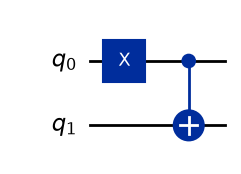

In [1]:
from qiskit import QuantumCircuit
from IPython.display import display

# Create a two-qubit circuit
qc = QuantumCircuit(2)

# Initial state: q_0 = |1>, q_1 = |0>
qc.x(0)

# Apply CNOT: cx(control, target)
# First parameter (0): control qubit q_0
# Second parameter (1): target qubit q_1
qc.cx(0, 1)

# Draw the circuit
display(qc.draw(output="mpl"))

## Deutsch's Algorithm: Applying CNOT

We now know how the **CNOT gate** works. Let's return to Deutsch's algorithm and investigate the oracle for $f(x)=x$.
- Recall that, for this function, **$U_f$ is exactly the CNOT gate**.

### Exercise 1: Review the Circuit

Look again at Deutsch's circuit:

- Can you identify where **CNOT** appears?
- Which qubit is the **control**, and which is the **target**?

### Exercise 2: Before and After the Oracle

Recall that our system starts in $\ket{0}\ket{1}$, and both qubits pass through an $H$ gate.

**1. What is the state of the entire system immediately before the oracle?**

$$
\ket{\psi_{\text{before}}} = \; ?
$$

**2. Apply CNOT to each basis state in the superposition. What is the resulting state?**

$$
\ket{\psi_{\text{after}}}
= U_f\ket{\psi_{\text{before}}}
= \; ?
$$

**3. Can you express the resulting state as a tensor product of two single-qubit states?**

**Think ahead:** What has changed after the oracle, and what information might this change reveal about $f$?

---

## Deutsch's Algorithm: Identifying CNOT

Recall that for $f(x)=x$, the oracle $U_f$ is a **CNOT gate**:

$$
U_f\ket{x}\ket{y}=\ket{x}\ket{y\oplus x}
$$

- **Control:** First qubit, $q_0$.
- **Target:** Second qubit, $q_1$.
- The target flips only when the control is $\ket{1}$.

Therefore, in Deutsch's circuit, we can replace the oracle $U_f$ with CNOT.

**Remember:** CNOT is reversible, and applying it twice restores the original state.

---

## Deutsch's Algorithm: Applying the Oracle

Immediately before the oracle, our system is in the state:

$$
\ket{\psi_{\text{before}}}
=\ket{+}\ket{-}
=\frac{1}{2}(\ket{00}-\ket{01}+\ket{10}-\ket{11})
$$

Applying CNOT to each basis state:

$$
\begin{aligned}
U_f\ket{\psi_{\text{before}}}
&=\frac{1}{2}(U_f\ket{00}-U_f\ket{01}+U_f\ket{10}-U_f\ket{11})\\[6pt]
&=\frac{1}{2}(\ket{00}-\ket{01}+\ket{11}-\ket{10})
\end{aligned}
$$

Therefore:

$$
\boxed{
\ket{\psi_{\text{after}}}
=\frac{1}{2}(\ket{00}-\ket{01}-\ket{10}+\ket{11})
}
$$

> **Think About It**: Decompose this state into two separate qubits.

---

## Deutsch's Algorithm: What Has Changed?

Recall the state after the oracle:

$$
\ket{\psi_{\text{after}}}
=\frac{1}{2}(\ket{00}-\ket{01}-\ket{10}+\ket{11})
$$

We can factor this expression:

$$
\begin{aligned}
\ket{\psi_{\text{after}}}
&=\frac{1}{2}(\ket{0}-\ket{1})(\ket{0}-\ket{1})\\[6pt]
&=\boxed{\ket{-}\ket{-}}
\end{aligned}
$$

Compare the states:

$$
\underbrace{\ket{+}\ket{-}}_{\text{Before oracle}}
\quad \longrightarrow \quad
\underbrace{\ket{-}\ket{-}}_{\text{After oracle}}
$$

**What do we observe?**

- The first qubit changes from $\ket{+}$ to $\ket{-}$.
- The second qubit remains $\ket{-}$.
- The oracle has changed the **relative phase** of the first qubit.

**Think ahead:** How can we detect this change using the $H$ gate?

This is the key idea behind how Deutsch's algorithm extracts information about $f$.

## Deutsch's Algorithm: What Has Changed?

Recall the state after the oracle:

$$
\ket{\psi_{\text{after}}}
=\frac{1}{2}(\ket{00}-\ket{01}-\ket{10}+\ket{11})
$$

We can factor this expression:

$$
\begin{aligned}
\ket{\psi_{\text{after}}}
&=\frac{1}{2}(\ket{0}-\ket{1})(\ket{0}-\ket{1})\\[6pt]
&=\boxed{\ket{-}\ket{-}}
\end{aligned}
$$

Compare the states:

$$
\underbrace{\ket{+}\ket{-}}_{\text{Before oracle}}
\quad \longrightarrow \quad
\underbrace{\ket{-}\ket{-}}_{\text{After oracle}}
$$

### What Do We Observe?

- The **first qubit** has changed from $\ket{+}$ to $\ket{-}$.
- The **second qubit** remains in $\ket{-}$.
- This change in the first qubit may help us identify that our function is **balanced**.

**Think ahead:** How can we use the $H$ gate to detect this change?

---

## Deutsch's Algorithm: What If the Function Is Constant?

So far, we explored the oracle for $f(x)=x$, a **balanced function**. Now, let's investigate a different case.

### Before and After the Oracle

Recall that the state immediately before the oracle is:

$$
\ket{\psi_{\text{before}}}
=\ket{+}\ket{-}
=\frac{1}{2}(\ket{00}-\ket{01}+\ket{10}-\ket{11})
$$

Applying the oracle:

$$
\begin{aligned}
\ket{\psi_{\text{after}}}
&=U_f\ket{\psi_{\text{before}}}
&=\frac{1}{2}(U_f\ket{00}-U_f\ket{01}+U_f\ket{10}-U_f\ket{11})
\end{aligned}
$$

### Exercise: What If $f$ Is Constant?

A function is **constant** when it produces the same output for every input:

- $f_0(0)=0,\quad f_0(1)=0$
- $f_1(0)=1,\quad f_1(1)=1$

Recall the oracle definition:

$$
U_f\ket{x}\ket{y}=\ket{x}\ket{y\oplus f(x)}
$$

**Your tasks:**

1. Determine $\ket{\psi_{\text{after}}}$ for $f_0$.
2. Repeat for $f_1$.
3. Express both resulting states using $\ket{+}$ and $\ket{-}$.
4. Compare your results with the balanced case. **What do you notice about the first qubit?**

**Think ahead:** Can the state of the first qubit tell us whether the function is constant or balanced?

---

## Deutsch's Algorithm: A Constant Function

Let's consider the constant function $f_0(x)=0$ for both inputs.

Recall the state before the oracle:

$$
\ket{\psi_{\text{before}}}
=\frac{1}{2}(\ket{00}-\ket{01}+\ket{10}-\ket{11})
$$

### Applying the Oracle

Since $f_0(x)=0$, the oracle leaves every basis state unchanged:

$$
U_f\ket{x}\ket{y}=\ket{x}\ket{y\oplus 0}=\ket{x}\ket{y}
$$

Therefore:

$$
\begin{aligned}
\ket{\psi_{\text{after}}}
&=\frac{1}{2}(\ket{00}-\ket{01}+\ket{10}-\ket{11})\\[6pt]
&=\frac{1}{2}(\ket{0}+\ket{1})(\ket{0}-\ket{1})\\[6pt]
&=\boxed{\ket{+}\ket{-}}
\end{aligned}
$$

### What Do We Observe?

Compare the states:

$$
\underbrace{\ket{+}\ket{-}}_{\text{Before oracle}}
\quad \longrightarrow \quad
\underbrace{\ket{+}\ket{-}}_{\text{After oracle}}
$$

- The **first qubit remains** in $\ket{+}$.
- Recall that for $f(x)=x$ (balanced), the first qubit changed to $\ket{-}$.

**Our observation:** The first qubit remains $\ket{+}$ for this constant function but changes to $\ket{-}$ for the balanced function we studied.

**Think ahead:** Can we use this difference to distinguish constant and balanced functions?

---

## Deutsch's Algorithm: Why Apply $H$ After the Oracle?

We have discovered something interesting about the **first qubit** after applying the oracle:

- **Constant function:** The first qubit is $\ket{+}$.
- **Balanced function:** The first qubit is $\ket{-}$ (possibly with an overall minus sign).

But there is a problem: **measuring either state gives $0$ or $1$ with equal probability!**

So, how can we distinguish them?

### The Hadamard Gate to the Rescue

Recall our transformation table for $H$:

$$
H\ket{+}=\ket{0}, \qquad H\ket{-}=\ket{1}
$$

Applying $H$ to the first qubit **after the oracle** gives:

| Function | After Oracle (First Qubit) | After $H$ |
|---|---|---|
| Constant | $\ket{+}$ | $\ket{0}$ |
| Balanced | $\ket{-}$ | $\ket{1}$ |

### What Have We Achieved?

We have transformed two states that are difficult to distinguish by computational-basis measurement into two states with **definite measurement outcomes**.

$$
\boxed{
\text{Constant} \rightarrow \ket{0}
\qquad
\text{Balanced} \rightarrow \ket{1}
}
$$

**We are now ready to measure the first qubit and discover whether $f$ is constant or balanced!**

---

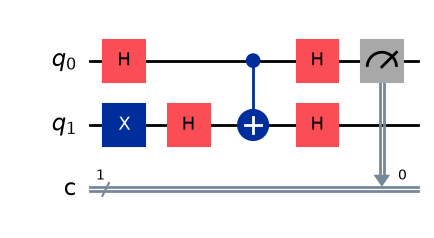

In [5]:
from qiskit import QuantumCircuit
from IPython.display import display

# Create a circuit with 2 qubits and 1 classical bit
qc = QuantumCircuit(2, 1)

# Initialize: q_0 = |0>, q_1 = |1>
qc.x(1)

# Apply Hadamard to both qubits
qc.h(0)
qc.h(1)

# Oracle: balanced function f(x) = x
# CNOT: q_0 is control, q_1 is target
qc.cx(0, 1)

# Apply Hadamard to the first and second qubits
qc.h(0)
qc.h(1)

# Measure the first qubit
qc.measure(0, 0)

# Draw the circuit
display(qc.draw(output="mpl"))

#Todo: try this circuit in IBM quantum platform

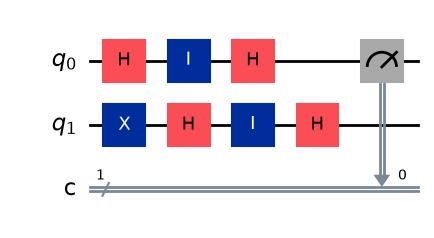

In [6]:
from qiskit import QuantumCircuit
from IPython.display import display

# Create a circuit with 2 qubits and 1 classical bit
qc = QuantumCircuit(2, 1)

# Initialize: q_0 = |0>, q_1 = |1>
qc.x(1)

# Apply Hadamard to both qubits
qc.h(0)
qc.h(1)

# Oracle: constant function f(x) = 0
# Identity operation: leave both qubits unchanged
qc.id(0)
qc.id(1)

# Apply Hadamard to the first and second qubits
qc.h(0)
qc.h(1)

# Measure the first qubit
qc.measure(0, 0)

# Draw the circuit
display(qc.draw(output="mpl"))

#Todo: try this circuit in IBM quantum platform

<br>
<div style="text-align: center;margin: 35px 0;font-size: 30px;font-weight: 600;letter-spacing: 3px;">

    ✦ PART FOUR ✦

</div>